# 11 — Figure S2: which flux terms carry the change in F_net,W−E?

F_net is the exact sum of six terms (see `05`), so for every event the
anomaly of the west–east contrast splits exactly:

ΔF_net,W−E = Σ_i ΔF_i,W−E   (Δ = run − control).

Across the 23 events, the least-squares slope of ΔF_i,W−E on ΔF_net,W−E is
the share of the F_net change carried by term *i*. Because the terms add up,
these shares add up to exactly 1 for each run — an attribution with no
residual and no choice of event.

Needs only the two tables in `data/`. Output: `figures/figS2_fnet_attribution.png` / `.pdf`
and the numbers in `figures/figS2_fnet_attribution.csv`.

In [5]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    "font.size": 8, "font.family": "sans-serif",
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

COMPONENTS = ["Latent", "F_cld", "F_clr", "Surf_SW", "Sensible", "Surf_LW"]
LABELS = {"Latent": "surface latent heat", "F_cld": "TOA cloud radiative effect", "F_clr": "TOA clear-sky radiation",
          "Surf_SW": "surface shortwave", "Sensible": "surface sensible heat", "Surf_LW": "surface longwave"}
RUNS = {"Full Run": "FULL", "Pattern Run": "PATTERN", "Uniform Run": "UNIFORM"}

## Step 1 — shares of ΔF_net,W−E per term and run

In [6]:
df = pd.read_csv(cfg.ANALYSIS_CSV_PATH)
clim = pd.read_csv(cfg.CLIMATOLOGY_CSV_PATH)

rows = []
for run, run_name in RUNS.items():
    sub = df[df["Run"] == run].set_index("Year")
    d_net = sub["westminuseast_F_net"] - clim.loc[0, "westminuseast_F_net"]
    for comp in COMPONENTS:
        d_comp = sub[f"westminuseast_{comp}"] - clim.loc[0, f"westminuseast_{comp}"]
        r = stats.linregress(d_net, d_comp)
        rows.append(dict(run=run_name, component=comp, share=r.slope, share_se=r.stderr, r2=r.rvalue ** 2,
                         std_d_fnet=d_net.std()))
shares = pd.DataFrame(rows)

check = shares.groupby("run")["share"].sum()
assert np.allclose(check, 1.0, atol=1e-2), check
print(shares.pivot(index="component", columns="run", values="share").loc[COMPONENTS].round(3).to_string())
print("\nstd of ΔF_net,W-E across events (W/m2):", shares.groupby("run")["std_d_fnet"].first().round(1).to_dict())

run         FULL  PATTERN  UNIFORM
component                         
Latent     0.490    0.494    0.521
F_cld      0.281    0.264   -0.048
F_clr      0.099    0.101    0.076
Surf_SW    0.088    0.099    0.377
Sensible   0.047    0.048    0.082
Surf_LW   -0.005   -0.005   -0.007

std of ΔF_net,W-E across events (W/m2): {'FULL': 27.5, 'PATTERN': 28.7, 'UNIFORM': 3.5}


## Step 2 — figure

saved figures/figS2_fnet_attribution.png
saved figures/figS2_fnet_attribution.pdf


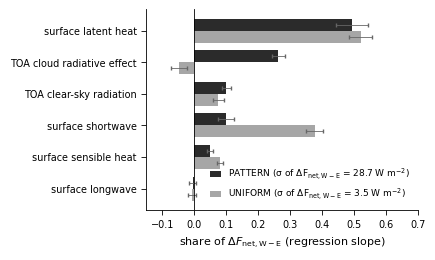

In [7]:
fig, ax = plt.subplots(figsize=(3.5, 2.6))
y = np.arange(len(COMPONENTS))
height = 0.38
style = {"PATTERN": dict(color="#2b2b2b", offset=-height / 2), "UNIFORM": dict(color="#a6a6a6", offset=height / 2)}

for run_name, st in style.items():
    sub = shares[shares["run"] == run_name].set_index("component").loc[COMPONENTS]
    sd = sub["std_d_fnet"].iloc[0]
    ax.barh(y + st["offset"], sub["share"], height=height, color=st["color"], xerr=1.96 * sub["share_se"],
            error_kw=dict(elinewidth=0.6, capsize=1.5, ecolor="0.4"),
            label=f"{run_name} (σ of ΔF$_{{\\rm net,W-E}}$ = {sd:.1f} W m$^{{-2}}$)")

ax.axvline(0, color="black", linewidth=0.6)
ax.set_yticks(y)
ax.set_yticklabels([LABELS[c] for c in COMPONENTS])
ax.invert_yaxis()
ax.set_xlim(-0.15, 0.7)
ax.set_xlabel(r"share of $\Delta F_{\rm net,W-E}$ (regression slope)")
ax.legend(loc="lower right", frameon=False, fontsize=6.5, handlelength=1.2)
ax.spines[["top", "right"]].set_visible(False)

os.makedirs(cfg.FIGURES_DIR, exist_ok=True)
for ext in ["png", "pdf"]:
    out_path = os.path.join(cfg.FIGURES_DIR, f"figS2_fnet_attribution.{ext}")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print("saved", os.path.relpath(out_path, cfg.REPO_ROOT))
shares.to_csv(os.path.join(cfg.FIGURES_DIR, "figS2_fnet_attribution.csv"), index=False, float_format="%.4g")
plt.show()

## Step 3 — does FULL follow PATTERN term by term?

In [8]:
full = df[df["Run"] == "Full Run"].set_index("Year")
pattern = df[df["Run"] == "Pattern Run"].set_index("Year")
for comp in COMPONENTS + ["F_net"]:
    col = f"westminuseast_{comp}"
    base = clim.loc[0, col]
    r = stats.linregress(pattern[col] - base, full[col] - base)
    print(f"{comp:9s} FULL vs PATTERN: slope = {r.slope:.2f}, r2 = {r.rvalue**2:.3f}")

Latent    FULL vs PATTERN: slope = 0.95, r2 = 0.991
F_cld     FULL vs PATTERN: slope = 1.02, r2 = 0.997
F_clr     FULL vs PATTERN: slope = 0.95, r2 = 0.990
Surf_SW   FULL vs PATTERN: slope = 0.93, r2 = 0.900
Sensible  FULL vs PATTERN: slope = 0.92, r2 = 0.950
Surf_LW   FULL vs PATTERN: slope = 0.95, r2 = 0.950
F_net     FULL vs PATTERN: slope = 0.95, r2 = 0.992
